--- Creating visualization for track: MONZA ---
   'Distance' column not found. Calculating it now...

--- Coordinate Data Summary ---
                 x            y            z     Distance
count  3750.000000  3750.000000  3750.000000  3750.000000
mean    228.079706   348.822267    -4.678791  2884.360264
std     396.861940   669.702427     3.604810  1655.690832
min    -212.184204  -887.496643   -11.272163     0.000000
25%    -105.187340  -228.112587    -7.586716  1453.818611
50%      89.384518   450.775070    -4.576991  2883.932559
75%     532.738602   965.616013    -1.672047  4313.999370
max    1046.555054  1277.567749     1.620336  5753.445317
-----------------------------

Data loaded successfully. Generating plot...
[Info] Debug probability file not found. Skipping confidence plot.

Plot successfully saved to: h:\My Drive\Cranfield\11. Individual Thesis\Code\Plots\Real\target_sections_vis_monza.png


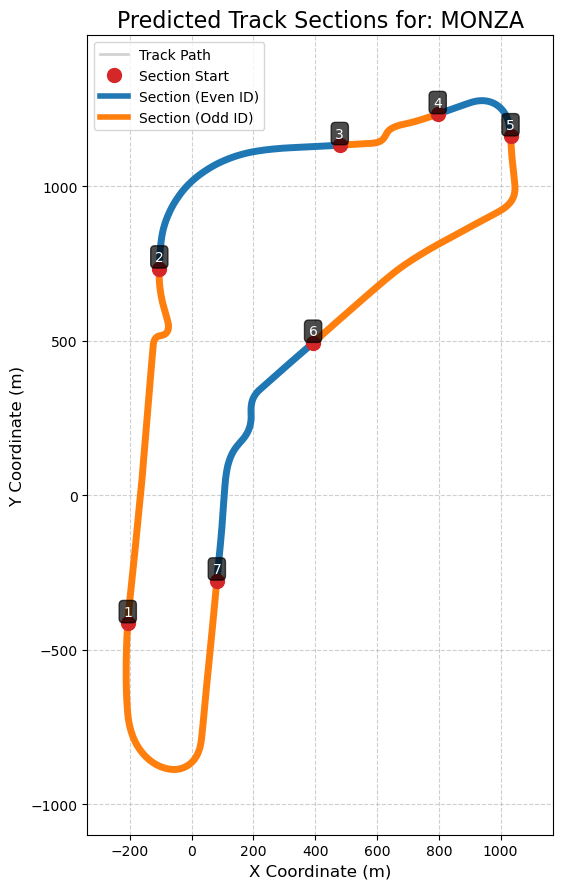

--- Visualization complete. ---


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =============================================================================
# --- 1. CONFIGURATION BLOCK ---
# =============================================================================
TRACK_NAME = "monza" 
USE_DUMMY_DATA = False # Using Real Data
SAVE_PLOT_TO_FILE = True

# =============================================================================
# --- 2. HELPER FUNCTION ---
# =============================================================================
def ensure_distance_column(df_coords):
    if 'Distance' in df_coords.columns:
        return df_coords
    print("   'Distance' column not found. Calculating it now...")
    points = df_coords[['x', 'y', 'z']].to_numpy()
    distances = np.linalg.norm(np.diff(points, axis=0), axis=1)
    cumulative_distance = np.insert(np.cumsum(distances), 0, 0)
    df_coords['Distance'] = cumulative_distance
    return df_coords

# =============================================================================
# --- 3. MAIN VISUALIZATION SCRIPT (with Robust Axis Scaling) ---
# =============================================================================

if __name__ in "__main__":
    print(f"--- Creating visualization for track: {TRACK_NAME.upper()} ---")

    # --- Setup and Load Paths ---
    data_type = "Dummy" if USE_DUMMY_DATA else "Real"
    base_path = os.getcwd()
    coord_path = os.path.join(base_path, "Coordinates", f"{TRACK_NAME}.csv")
    sections_path = os.path.join(base_path, "Sections", data_type, f"sections_target_{TRACK_NAME}.csv")
    debug_path = os.path.join(base_path, "Sections", data_type, f"sections_debug_{TRACK_NAME}.csv")
    
    try:
        df_coords = pd.read_csv(coord_path)
        df_sections = pd.read_csv(sections_path)
    except FileNotFoundError as e:
        print(f"\n[FATAL ERROR] Could not find a required file: {e}")
        exit()

    df_coords = ensure_distance_column(df_coords)
    
    # --- NEW: DEBUGGING PRINTOUT ---
    # This will print a summary of your coordinate data. Check the 'max' and 'min' values.
    # If you see a very large number (e.g., 1.000000e+12), it indicates a data corruption issue.
    print("\n--- Coordinate Data Summary ---")
    print(df_coords[['x', 'y', 'z', 'Distance']].describe())
    print("-----------------------------\n")

    print("Data loaded successfully. Generating plot...")
    fig, ax = plt.subplots(figsize=(16, 9))

    # --- Plotting Track and Sections ---
    ax.plot(df_coords['x'], df_coords['y'], color='lightgrey', linewidth=2, zorder=1, label='Track Path')
    section_colors = ['#1f77b4', '#ff7f0e']
    for _, section in df_sections.iterrows():
        color = section_colors[int(section['segment_id']) % 2]
        section_data = df_coords[(df_coords['Distance'] >= section['start_m']) & (df_coords['Distance'] <= section['end_m'])]
        if not section_data.empty:
            ax.plot(section_data['x'], section_data['y'], color=color, linewidth=5, zorder=2)
        start_point_index = (df_coords['Distance'] - section['start_m']).abs().idxmin()
        start_point = df_coords.iloc[start_point_index]
        ax.plot(start_point['x'], start_point['y'], 'o', color='#d62728', markersize=10, zorder=3)
        ax.text(start_point['x'], start_point['y'] + 15, str(int(section['segment_id'])), color='white', ha='center', va='bottom', fontsize=10, bbox=dict(facecolor='black', alpha=0.7, pad=2, boxstyle='round,pad=0.3'))
    
    # --- NEW: ROBUST AXIS SCALING ---
    # This block manually calculates the plot boundaries, ignoring any extreme outliers.
    # We use percentiles to find the range of the main bulk of the data.
    x_min = df_coords['x'].quantile(0.01)
    x_max = df_coords['x'].quantile(0.99)
    y_min = df_coords['y'].quantile(0.01)
    y_max = df_coords['y'].quantile(0.99)
    
    # Add a small margin for padding
    x_margin = (x_max - x_min) * 0.1
    y_margin = (y_max - y_min) * 0.1
    
    # Set the plot limits manually
    ax.set_xlim(x_min - x_margin, x_max + x_margin)
    ax.set_ylim(y_min - y_margin, y_max + y_margin)
    # --- END OF FIX ---

    # --- Plotting Probability (if debug file exists) ---
    try:
        df_debug = pd.read_csv(debug_path)
        # Create a second plot for the probability confidence
        ax2 = fig.add_axes(ax.get_position())
        ax2.patch.set_visible(False) # Make the background transparent
        ax2.yaxis.set_label_position('right')
        ax2.yaxis.set_ticks_position('right')

        # This plot will be distance vs probability
        ax2.plot(df_debug['Distance'], df_debug['start_probability'], color='green', linestyle='--', linewidth=1.5, label='Model Confidence')
        ax2.set_ylabel('Probability', color='green', fontsize=12)
        ax2.tick_params(axis='y', labelcolor='green')
        ax2.set_ylim(0, 1)
        ax2.axhline(y=0.65, color='red', linestyle=':', linewidth=2, label='Confidence Threshold (0.65)')
        ax2.set_xlabel("Track Distance (m)", fontsize=12)
    except FileNotFoundError:
        print("[Info] Debug probability file not found. Skipping confidence plot.")

    # --- Formatting and Final Touches ---
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(f"Predicted Track Sections for: {TRACK_NAME.upper()}", fontsize=16)
    ax.set_xlabel("X Coordinate (m)", fontsize=12)
    ax.set_ylabel("Y Coordinate (m)", fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.6)
    
    # --- Legend ---
    from matplotlib.lines import Line2D
    legend_elements = [ Line2D([0], [0], color='lightgrey', lw=2, label='Track Path'),
                        Line2D([0], [0], marker='o', color='#d62728', label='Section Start', linestyle='None', markersize=10),
                        Line2D([0], [0], color=section_colors[0], lw=4, label='Section (Even ID)'),
                        Line2D([0], [0], color=section_colors[1], lw=4, label='Section (Odd ID)')]
    if 'ax2' in locals():
        lines, labels = ax2.get_legend_handles_labels()
        legend_elements.extend(lines)
    ax.legend(handles=legend_elements, loc='best')

    plt.tight_layout()
    if SAVE_PLOT_TO_FILE:
        # ... (saving logic remains the same)
        plot_folder = os.path.join(base_path, "Plots", data_type)
        os.makedirs(plot_folder, exist_ok=True)
        output_filename = f"target_sections_vis_{TRACK_NAME}.png"
        output_path = os.path.join(plot_folder, output_filename)
        plt.savefig(output_path, dpi=300, bbox_inches='tight')
        print(f"\nPlot successfully saved to: {output_path}")

    plt.show()

    print("--- Visualization complete. ---")